# Homework 1 Python Programming

Last updated: Sep 5, 2025

## Learning Objectives
In our first assignment, we will implement an ID3 decision tree to fit and predict on both categorial and numerical features.

## Setup

**IMPORTANT**: Before you edit this notebook, you will need to make your own copy (otherwise your edits **will not be saved**).  You can do so by clicking the "File" dropdown in the upper left, and then selecting "Save a copy in Drive" as shown in the screenshot below.

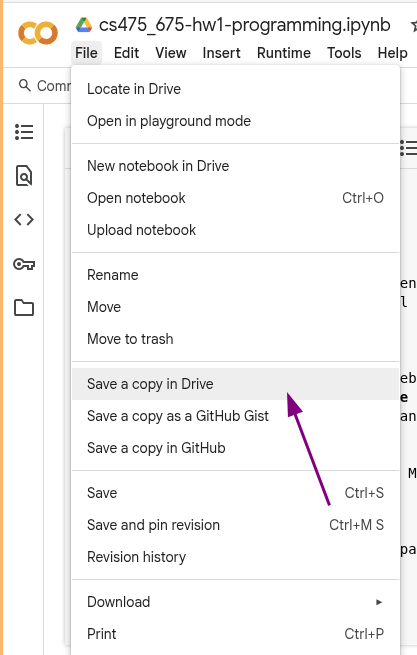

Once you have done so, **change the filename to remove "Copy of..."** so that the filename is the same as the original file.
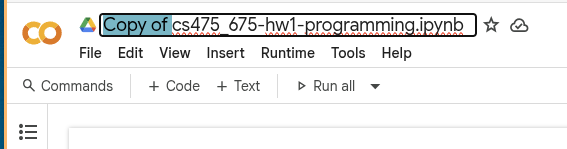

You should now see the following in the upper left of your screen

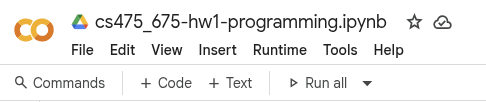

And you're ready to go!

## Instructions
Please complete the following problems. Make sure to run all cells before submission.

## Setup
Run the cell below to install required packages (if needed).

In [1]:
# Install required packages
%pip install -q numpy pandas matplotlib scikit-learn datasets

## Student Information
**IMPORTANT**: Fill in your information in the cell below before starting the assignment.

In [1]:
# IMPORTANT: This cell contains metadata for grading. Do not delete this cell.
# STUDENT INFORMATION - REQUIRED
# Fill in your information below

JHED_ID = "csmit469"  # Your JHED ID (e.g., "zhuang86" - the part before @jhu.edu)
COLAB_LINK = "https://colab.research.google.com/drive/1KHCqv5BYhgt52YDHKoC5NRjNmARyj5BZ?usp=sharing"  # Public sharing link to this Colab notebook
                  # To get this: "Share" on upper right corner -> "Copy link" (make sure it's set to "Anyone with the link")

# Verify your information is entered
assert JHED_ID != "", "Please enter your JHED ID"
assert COLAB_LINK != "", "Please enter your Colab sharing link"
assert "colab.research.google.com" in COLAB_LINK or COLAB_LINK == "LOCAL", "Please enter a valid Colab link or 'LOCAL' if testing locally"

print(f"JHED ID: {JHED_ID}")
print(f"Colab Link: {COLAB_LINK}")

JHED ID: csmit469
Colab Link: https://colab.research.google.com/drive/1KHCqv5BYhgt52YDHKoC5NRjNmARyj5BZ?usp=sharing


In [2]:
# Setup and imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from datasets import load_dataset
from typing import Optional, Union, Any, Tuple, List, Type

## Part 1: Decision Tree


In this part, we will work with a toy dataset that records decisions on whether to play tennis depending on weather conditions. We will implement a binary decision tree classifier (ID3 algorithm) to make predictions.

In [3]:
colums = ['Outlook', 'Temperature', 'Humidity', 'Wind', 'Play']
data = [['Sunny', 'Hot', 'High', 'Weak', 'No'],
       ['Sunny', 'Hot', 'High', 'Strong', 'No'],
       ['Overcast', 'Hot', 'High', 'Weak', 'Yes'],
       ['Rain', 'Mild', 'High', 'Weak', 'Yes'],
       ['Rain', 'Cool', 'Normal', 'Weak', 'Yes'],
       ['Rain', 'Cool', 'Normal', 'Strong', 'No'],
       ['Overcast', 'Cool', 'Normal', 'Strong', 'Yes'],
       ['Sunny', 'Mild', 'High', 'Weak', 'No'],
       ['Sunny', 'Cool', 'Normal', 'Weak', 'Yes'],
       ['Rain', 'Mild', 'Normal', 'Weak', 'Yes'],
       ['Sunny', 'Mild', 'Normal', 'Strong', 'Yes'],
       ['Overcast', 'Mild', 'High', 'Strong', 'Yes'],
       ['Overcast', 'Hot', 'Normal', 'Weak', 'Yes'],
       ['Rain', 'Mild', 'High', 'Strong', 'No']]
dataset = pd.DataFrame(data, columns = colums)
dataset

,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


The `TreeNode` class represents a node in a decision tree. Each node has a feature with the corresponding splitting value, and two children nodes. The class TreeBase provides the basic structure of a decision tree, and the class DecisionTree inherits from TreeBase, which you need to complete the missing parts.

In [4]:
class TreeNode: # Do not modify this class
    '''
    A node class for a decision tree.
    '''
    def __init__(self,
                 feature: Optional[str] = None,
                 value: Optional[Union[str, float]] = None,
                 left: Optional['TreeNode'] = None,
                 right: Optional['TreeNode'] = None,
                 label: Optional[Any] = None) -> None:
        self.feature: Optional[str] = feature # feature to split on
        self.value: Optional[Union[str, float]] = value # value used for splitting
        self.left: Optional['TreeNode'] = left # left child
        self.right: Optional['TreeNode'] = right # right child
        self.label: Optional[Any] = label # label for the node


class TreeBase: # Do not modify this class
    def __init__(self, data: pd.DataFrame, label: str, max_depth: int = 5) -> None:
        '''
        TreeBase implements part of the functionality for the decision tree classifier
        '''
        self.data: pd.DataFrame = data
        self.root: Optional[TreeNode] = None
        self.max_depth: int = max_depth
        self.label: str = label
        self.features: pd.Index = data.columns.drop(label)

    def select_best_feature(self, data: pd.DataFrame, features: pd.Index) -> Tuple[Optional[str], Optional[Union[str, float]]]:
        '''
        Selects the feature with the highest information gain
        Args:
            data (`DataFrame`): the data for the tree
            features (`pd.Index`): list of features
        Returns:
            best_feature (`str`): the feature with the highest information gain
            best_value (`str`): the value of the best feature
        '''
        best_gain: float = -1  # Start with -1 to ensure we select at least one split
        best_feature: Optional[str] = None
        best_value: Optional[Union[str, float]] = None

        for feature in features: #Iterate over all features
            values = data[feature].unique() #Get all unique values of the feature
            for value in values: #Iterate over all values
                gain: float = self.information_gain(data, feature, value) #Calculate the information gain
                if gain > best_gain or best_feature is None:  # Select first split or better gain
                    best_gain = gain
                    best_feature = feature
                    best_value = value

        return best_feature, best_value

    def entropy(self, data: pd.DataFrame) -> float:
        raise NotImplementedError

    def information_gain(self, data: pd.DataFrame, feature: str, value: Union[str, float]) -> float:
        raise NotImplementedError

    def predict(self, data_point: pd.Series) -> Any:
        '''
        Predicts the label for a single instance
        Args:
            data_point (`pandas.Series`): with keys being the feature names
        Returns:
            label (`str`): the label of the instance
        '''
        node: Optional[TreeNode] = self.root
        label: Optional[Any] = None
        while True:
            if node.label is not None: #Leaf node
                label = node.label
                break
            if type(node.value) == str: #Categorical feature
                go_left: bool = data_point[node.feature] == node.value
            else: #Numerical feature
                go_left: bool = data_point[node.feature] < node.value

            if go_left:
                node = node.left
            else:
                node = node.right
        return label

    def fit(self) -> None:
        self.root = self.build_tree(TreeNode(), self.data, self.features, 0) #Build the tree

    def build_tree(self, node: TreeNode, data: pd.DataFrame, features: pd.Index, depth: int) -> Optional[TreeNode]:
        '''
        Recursively builds the decision tree
        Args:
            node (`TreeNode`): current node to be split
            data (`DataFrame`): the data for the tree
            features (`pd.Index`): list of features
            depth (`int`): the current depth of the tree
        Returns:
            node (`TreeNode`): the root of the built tree
        '''

        # Check if data is empty
        if len(data) == 0:
            return None

        #Stop if the entropy is 0, or the depth >= max_depth, or all data points has the same feature value.
        stop: bool = np.isclose(self.entropy(data), 0) or \
                 depth >= self.max_depth or \
                 (data.values[0] == data.values).all()
        if stop:
            node = TreeNode()
            node.label = data[self.label].mode()[0] # Get the most common label, only set label for leaf nodes
            return node

        feature, value = self.select_best_feature(data, features)
        node = TreeNode(feature=feature, value=value)
        if isinstance(value, str): # Categorical feature
            left_data, right_data = data[data[feature] == value], data[data[feature] != value]
        else: #Numerical feature
            left_data, right_data = data[data[feature] < value], data[data[feature] >= value]

        # If one split is empty, make this a leaf node
        if len(left_data) == 0 or len(right_data) == 0:
            node = TreeNode()
            node.label = data[self.label].mode()[0]
            return node

        node.left = self.build_tree(node.left, left_data, features, depth + 1)
        node.right = self.build_tree(node.right, right_data, features, depth + 1)
        return node

    def print_tree(self) -> None:
        '''
        Prints the tree
        '''
        self._print_tree(self.root, 0)

    def _print_tree(self, node: Optional[TreeNode], depth: int) -> None:
        '''
        Recursively prints the tree
        Args:
            node (`Optional[TreeNode]`): the current node
            depth (`int`): the current depth of the tree
        '''
        if node is None:
            return
        if node.label is not None:
            print(" " * depth, node.label)
        else:
            if isinstance(node.value, str):
                print(" " * depth, node.feature, "=", node.value)
            else:
                print(" " * depth, node.feature, "<", node.value)
            self._print_tree(node.left, depth + 1)
            self._print_tree(node.right, depth + 1)

### 1.1 Decicion Tree Implementation

Now, let's implement the missing part.

In [6]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.


class DecisionTree(TreeBase):
    '''
    Binary decision tree class, inherits from TreeBase
    '''
    def __init__(self, data: pd.DataFrame, label: str, max_depth: int = 5) -> None:
        super(DecisionTree, self).__init__(data, label, max_depth)

    def entropy(self, data: pd.DataFrame) -> float:
        '''
        Calculates the entropy of the data
        Args:
            data (`DataFrame`): the data for the tree
        Returns:
            entropy (`float`): the entropy of the data
        '''

        # find feature we want to predict and its possible values
        predict_feature = self.label
        values = data[predict_feature].unique()

        total = len(data)
        entropy = 0

        for value in values: # iterate over all values
          # find probability of that value occuring
          p = len(data[data[predict_feature] == value]) / total

          # if p == 0, then the log cannot be evaluated (this quantity would
          # be 0, so we're not omitting data)
          if (p != 0):
            entropy -= p * math.log2(p)

        return entropy

    def information_gain(self, data: pd.DataFrame, feature: str, value: Union[str, float]) -> float:
        '''
        Calculates the information gain
        Args:
            data (`DataFrame`): the data for the tree
            feature (`str`): the feature to split
            value (`Union[str, float]`): the value of the feature
        Returns:
            information_gain (`float`): the information gain

        '''

        # isolate data where the given feature has the given value and find
        # H(Y | X) for it

        # split data into two categories: feature = or < value or feature != or
        # >= value
        if isinstance(value, str):
          var_one = data[data[feature] == value]
          var_zero = data[data[feature] != value]
        else:
          var_one = data[data[feature] < value]
          var_zero = data[data[feature] >= value]

        total = len(data)
        one = len(var_one)
        zero = len(var_zero)

        # find H(Y | X), where X is an indicator variable for the
        # feature being = or < given value
        sum_values = (one / total) * self.entropy(var_one) + (zero / total) * self.entropy(var_zero)

        # gain = H(Y) - H(Y | X)
        information_gain = self.entropy(data) - sum_values

        return information_gain


We provide the code to test the decision tree on the tennis dataset. You can add more tests to check your implementation. We will not grade your additional tests and may run additional test cases, but we encourage you to do so to ensure your implementation is correct.

In [7]:
# Test your implementation
dt = DecisionTree(dataset, 'Play', 5)
data_test1 = dataset.iloc[:6]
assert np.isclose(dt.entropy(data_test1), 1.0) # Test entropy implementation
dt.fit() # Test build the tree and make sure there is no error
dt.print_tree() # Print the tree

 Outlook = Overcast
  Yes
  Humidity = High
   Outlook = Sunny
    No
    Wind = Weak
     Yes
     No
   Wind = Weak
    Yes
    Outlook = Rain
     No
     Yes


In [8]:
sample = dataset.iloc[0]
print(sample)
print('----------')
print('prediction:', dt.predict(sample)) # Test predict function

Outlook        Sunny
Temperature      Hot
Humidity        High
Wind            Weak
Play              No
Name: 0, dtype: object
----------
prediction: No


### 1.2 Evaluation

Next, you will need to provide the code for evaluating the tree. The function take a tree model, and a dataset then output the accuracy of the decision tree on the dataset. The accuracy is defined as the number of correct predictions divided by the total number of predictions.

In [12]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.
def evaluate(dt: TreeBase, dataset: pd.DataFrame) -> float:
    '''
    Evaluates the decision tree
    Args:
        dt (`DecisionTree`): the decision tree
        dataset (`DataFrame`): the dataset
    Returns:
        accuracy (`float`): the accuracy of the model on the dataset
    '''

    correct = 0
    total = len(dataset) # total predictions

    for i in range(total):
      # make predicition for each row of data and compare
      prediction = dt.predict(dataset.iloc[i])

      if (prediction == dataset[dt.label].iloc[i]):
        correct += 1

    accuracy = correct / total

    return accuracy


In [13]:
# test evaluate function
print('accuracy:', evaluate(dt, dataset)) # Test evaluate function

accuracy: 1.0


# Part 2: The effect of tree complexity on the performance

Unlike the tennis dataset, which contains only categorical data, this part will involve working with numerical data. If you haven't already, modify your DecisionTree code to handle both categorical and numerical features. Your new implementation should not fail previous tests.

In this part, you would:
1. Update your DecisionTree class to handle numerical features.
1. Provide the code for training and evaluating the decision tree with various tree depths.
1. Plot the train and test accuracy.
1. Answer discussion questions.

The code below generates a dataset of 1,000 samples with binary class labels. As in the previous section, we will store the dataset in a pandas `DataFrame`.

In [14]:
# Don't modify this cell, we will use this code to generate synthetic data

X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7, random_state=42)
# Create a pandas DataFrame for the train/test data
columns = ['feature_' + str(i) for i in range(X_train.shape[1])] + ['label']
df_train = pd.DataFrame(np.column_stack((X_train, y_train)), columns=columns)
df_test = pd.DataFrame(np.column_stack((X_test, y_test)), columns=columns)
df_train.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,label
0,-0.272427,-0.029398,-0.636882,1.520092,-0.239273,1.569953,0.207139,-0.751345,-0.310397,-0.693804,...,-1.482397,0.884843,0.131119,-1.607711,2.051247,-1.954593,-0.099314,-0.527984,-1.569390,1.0
1,1.603702,-0.758917,-1.073091,0.405850,-1.308684,-0.445018,-0.848905,0.906784,0.913607,0.690701,...,-0.866448,-0.797485,-0.069852,2.329718,0.380520,0.459637,0.142688,-0.214368,-0.125819,0.0
2,0.725821,-0.498031,0.551256,0.612412,1.700972,0.462312,-1.139286,-0.370698,-0.271115,0.305701,...,-0.233880,-0.201946,0.550813,0.721858,-1.250026,0.349293,0.551437,-0.387667,0.923033,1.0
3,0.946618,0.029895,-0.335516,-0.216419,-1.119250,-0.057604,0.255977,-0.363176,0.369926,-0.270270,...,0.915824,-0.778309,-0.136422,-0.011394,-0.443429,0.934655,1.612868,0.033045,-0.140276,1.0
4,-0.249894,-0.725025,-0.426571,-0.404639,1.355805,0.683565,-0.389404,0.558695,0.280236,0.384209,...,-0.907327,-0.892773,-1.224387,1.039595,1.734042,0.292149,0.107760,-0.567810,-1.197958,1.0


Let's fit and evaluate our decision tree implementation on the new data.

In [15]:
# test fitting the decision tree
dt = DecisionTree(df_train, 'label', 3)
dt.fit()

# test evaluate function
train_acc_value, test_acc_value = evaluate(dt, df_train), evaluate(dt, df_test)
print('Train accuracy:', train_acc_value)
print('Test accuracy:', test_acc_value)

Train accuracy: 0.9
Test accuracy: 0.8628571428571429


### 2.1 Complexity

Now, we will try to understand the effect of the complexity of the tree on the performance. We will use the depth of the tree as a measure of complexity. We will train the decision tree with different depths and evaluate the performance on the training and testing datasets.

In [16]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.

def train_and_evaluate(tree_cls: Type[TreeBase],
                       max_depth: int,
                       df_train: pd.DataFrame,
                       df_test: pd.DataFrame,
                       label: str = 'label') -> Tuple[List[float], List[float]]:
    """
    Trains and evaluates the decision tree with different depths.
    Args:
        tree_cls (`DecisionTree`): the decision tree class
        max_depth (`int`): the maximum depth of the tree
        df_train (`DataFrame`): the training dataset
        df_test (`DataFrame`): the testing dataset
        label (`str`): the label of the dataset
    Returns:
        train_acc (`list`): the training accuracy for each depth
        test_acc (`list`): the testing accuracy for each depth
    """
    train_acc: List[float] = []
    test_acc: List[float] = []
    for tree_depth in range(max_depth + 1):
        dt: TreeBase = tree_cls(df_train, label, tree_depth)
        dt.fit()

        # evaluate accuracy for training and test data and add to list
        train_acc_value, test_acc_value = evaluate(dt, df_train), evaluate(dt, df_test)
        train_acc.append(train_acc_value)
        test_acc.append(test_acc_value)

    return train_acc, test_acc

In [17]:
max_depth = 10 # you can vary the depth, the larger the depth, the longer it will take to train. This is just our recommended number
train_acc, test_acc = train_and_evaluate(DecisionTree, max_depth, df_train, df_test)

### 2.2 Plots

Plot the train and test accuracy with the corresponding depth of the tree. The x axis should be the maximum depth of the tree, and the y axis should be the accuracy. You should have two plots, one for the training accuracy and one for the testing accuracy.

In [18]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.

def plot_accuracy(train_acc: List[float], test_acc: List[float], max_depth: int) -> None:
    """
    Plots the training and testing accuracy with the corresponding depth of the tree.
    Args:
        train_acc (`list`): the training accuracy for each depth
        test_acc (`list`): the testing accuracy for each depth
        max_depth (`int`): the maximum depth of the tree
    """

    # plot both training and test accuracy across tree depth
    plt.plot(range(max_depth + 1), train_acc, label = "train")
    plt.plot(range(max_depth + 1), test_acc, label = "test")
    plt.xlabel("Maximum Tree Depth")
    plt.ylabel("Prediction Accuracy")
    plt.title("Tree Depth vs. Accuracy for Training and Test Data")
    plt.legend()

    plt.show()


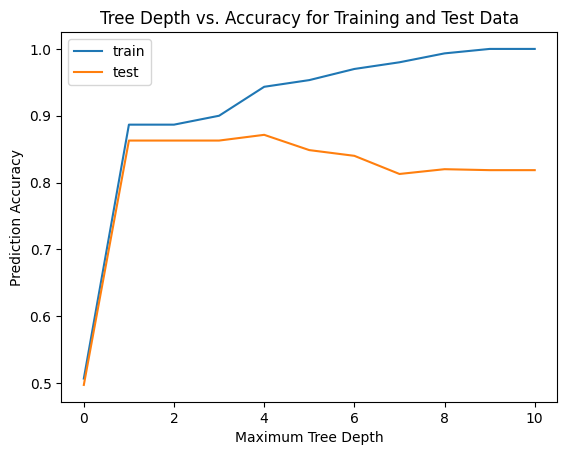

In [19]:
# Make sure to run this cell to plot the accuracy
# This will be manually graded
plot_accuracy(train_acc, test_acc, max_depth)

### 2.3 Short question

What do you observe from the plot? Discuss your findings based on the train and test accuracy when increasing the depth of the tree.

In [40]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.

# YOUR CODE HERE
ans_2_3 = "As tree depth increases, there is a point where the accuracy of both the train \nand the test results increases as well, but as the tree becomes more complex, \nthe gap between the two widens. This is because more complex trees can sometimes \nbe too accurate for the test data, so ideally we would choose a tree that is \njust complex enough to be somewhat accurate for both, which seems to be around \n1 - 3 in this case. Both of these qualities can be seen in the plot, where the \naccuracy of both increases and caps off at first with increasing tree depth, \nbut then the training accuracy approaches 1 (i.e. overfitting) as the test \naccuracy decreases due to too specific of a decision tree."
# END YOUR CODE

In [41]:
# Make sure to run this cell to plot the accuracy
# This will be manually graded
print(ans_2_3)

As tree depth increases, there is a point where the accuracy of both the train 
and the test results increases as well, but as the tree becomes more complex, 
the gap between the two widens. This is because more complex trees can sometimes 
be too accurate for the test data, so ideally we would choose a tree that is 
just complex enough to be somewhat accurate for both, which seems to be around 
1 - 3 in this case. Both of these qualities can be seen in the plot, where the 
accuracy of both increases and caps off at first with increasing tree depth, 
but then the training accuracy approaches 1 (i.e. overfitting) as the test 
accuracy decreases due to too specific of a decision tree.


## Part 3: Challenge [Extra Credit]

This part is completely optional.

Our current decision tree is very rudimentary and easily fails on some datasets with noise. There are many potential solutions, but pruning might be one of the most intuitive ways. In this part, you should understand how pruning works and implement a better decision tree that inherits from your previous version. Your implementation will be tested on a hidden dataset with a distribution unknown to you. The ID3 decision tree we just implemented will serve as a reasonable baseline, and your task is to improve upon it. Please note that the dataset contains more than two classes.

There will be a leaderboard on Gradescope, and once you submit your code, the autograder will run your code and generate a score. You may submit as many times as you want, but only the latest submission will be graded.

We also know that open-ended questions like this are "best questions" because AI (or large language models) can take care of everything. While you are not supposed to use any of the AI/LLM tools, we have already tried them for you. On the leaderboard, you will also see several submissions marked as `LLM 1`, `LLM 2`, etc. They reflect current state-of-the-art models' performance in this context. You do not have to beat them, but if you do, we are happy to offer additional credits if you are willing to share the implementation details with the class.

In [42]:
df_train = load_dataset("sheepy928/ml-475-675-hw1-train", split="train").to_pandas()
df_train.head()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/392k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,label
0,-1.234338,0.410770,0.376205,0.029437,0.138467,-0.409302,-1.979791,-1.206750,-1.210677,0.127118,...,0.138467,1.856233,-1.755647,-0.350994,0.685682,-1.010591,0.926171,-1.227163,3.817121,2.0
1,0.952126,-0.962316,-1.340122,-1.107813,2.123240,0.322858,0.977038,-2.342354,-6.041409,-2.660551,...,2.123240,-2.620684,-0.795270,0.438609,0.629367,0.366504,1.664647,0.851766,0.513818,3.0
2,-0.950120,0.501162,-0.472501,0.309138,-0.232650,0.062151,0.147292,-0.679676,-2.416335,-1.850218,...,-0.232650,-0.042177,-1.874056,-1.284945,0.079694,-0.176900,0.394112,1.078850,-0.830081,2.0
3,-0.053664,1.270812,-1.322118,0.359523,1.628966,-2.423747,0.933359,-0.611475,-4.852626,-3.090752,...,1.628966,-1.488646,0.483980,-0.423941,0.525640,-1.878857,0.245603,-0.465753,-1.918686,0.0
4,-1.301614,-0.076828,1.976577,-1.578400,0.534760,-0.228339,-0.653771,-0.305176,-1.943447,-0.954238,...,0.534760,1.425941,1.285078,-0.621609,-0.259872,-0.053596,-0.633014,-0.696619,0.386818,2.0


In [43]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.

class BetterDecisionTree(DecisionTree):
    # YOUR CODE HERE
    def __init__(self, data: pd.DataFrame, label: str, max_depth: int = 5) -> None:
        super(BetterDecisionTree, self).__init__(data, label, max_depth)

    # END YOUR CODE


If your `BetterDecisionTree` has additional hyperparameters, please make sure they are set to sensible defaults when they are not specified or provided in `dt_kwargs`. During testing, we will initialize a `BetterDecisionTree` object as

```python
dt_challenge = BetterDecisionTree(df_train, 'label', **dt_kwargs)
dt_challenge.fit()
```

In [46]:
# IMPORTANT: This cell contains metadata for grading.
# Everything in this cell will be used by the autograder.
# Do not delete this cell.

dt_kwargs = {
    'max_depth': 3,
}


In [47]:
dt_challenge = BetterDecisionTree(df_train, 'label', **dt_kwargs)
dt_challenge.fit()

## Submission

**IMPORTANT SUBMISSION INSTRUCTIONS:**
1. Make sure all cells are executed (Run All): This makes sure that your notebook does not produce errors. We will use the results produced by Gradescope autograder for grading.
2. Download this notebook: File -> Download -> Download .ipynb
3. Submit the .ipynb file to Gradescope
4. Do NOT rename the file when downloading
5. If your browser adds numbers like (1) or (2) to the filename, that's OK - the autograder will handle it